In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, rv_continuous, mannwhitneyu
from scipy.special import erf, erfc, logsumexp
from astropy.convolution import convolve, Gaussian1DKernel
from scipy.integrate import quad as integrator

In [2]:
N = 1000
PDF_X = np.logspace(1, np.log10(200), N)
gw_mean = 100
gw_std = 20

np_trapz_fn = np.trapz

In [3]:
class AsymmetricGaussian(rv_continuous):
    """
    Custom Asymmetric Gaussian distribution.
    Use loc for the mean, and unc_minus/unc_plus as shape parameters.
    """

    def _pdf(self, x, mean, unc_minus, unc_plus):
        """x is already shifted by loc internally by scipy, so we don't need to pass
        the mean"""
        pdf = np.where(
            x < mean,
            np.exp(-0.5 * (x / unc_minus) ** 2),
            np.exp(-0.5 * (x / unc_plus) ** 2),
        )

        norm = np.sqrt(2 / np.pi) * (unc_plus + unc_minus*erf(mean/(unc_minus*np.sqrt(2))))**-1
        return norm * pdf

In [4]:
import numpy as np
from scipy.special import erf, erfc

WEIGHT_R0 = 1.0           # sigma_gal/sigma_gw at which w == 0.5 exactly
# Logistic rate; k = 8 puts the handover band at r in [0.73, 1.27]. Measured on
# S251112cm: k >= 4 is needed for a well-centred spec-z host to clear 0.9, and
# ranking is insensitive to the exact value (Spearman > 0.99 across k = 0.5..32).
WEIGHT_K = 8.0
# -----------------------------------------------------------------------------

def normalization_prefactor(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos):
    prefactor_cand = np.sqrt(2/np.pi) * (sigma_cand_pos + sigma_cand_neg*erf(mean_cand/(sigma_cand_neg*np.sqrt(2))))**-1
    prefactor_gw = float(sigma_gw)**-1 * np.sqrt(2/np.pi) * (1 + erf(mean_gw/(sigma_gw*np.sqrt(2))))**-1
    return np.sqrt(prefactor_cand*prefactor_gw)

def a(sigma_gw, sigma_cand):
    return 1/sigma_gw**2 + 1/sigma_cand**2
        
def b(mean_gw, sigma_gw, mean_cand, sigma_cand):
    return mean_gw/sigma_gw**2 + mean_cand/sigma_cand**2

def p(mean_gw, sigma_gw, mean_cand, sigma_cand):
    """Gaussian prefactor of the half-integrals.

    The exponent is algebraically ``c - b**2/a``, but computed that way it
    catastrophically cancels once a sigma is orders of magnitude below the
    means: c and b**2/a both become enormous and nearly equal, so the
    difference overflows or returns noise. bc() has been observed returning
    inf and 8.7e101 for sigma_cand = 1e-7 Mpc. The identity

        c - b**2/a  ==  (mean_gw - mean_cand)**2 / (sigma_gw**2 + sigma_cand**2)

    is exact and never builds those large intermediates.
    """
    _a = a(sigma_gw, sigma_cand)
    exponent = (mean_gw - mean_cand)**2 / (sigma_gw**2 + sigma_cand**2)
    return np.sqrt(np.pi/_a) * np.exp(-0.25*exponent)

def bc_integral_neg(mean_gw, sigma_gw, mean_cand, sigma_cand_neg):
    """Integral over [0, mean_cand], where the candidate uses its lower tail."""
    _a = a(sigma_gw, sigma_cand_neg)
    _b = b(mean_gw, sigma_gw, mean_cand, sigma_cand_neg)

    _p = p(mean_gw, sigma_gw, mean_cand, sigma_cand_neg)
    x0 = erf(-_b/(2*np.sqrt(_a)))
    x1 = erf(np.sqrt(_a)/2 * (mean_cand - _b/_a))
    return _p*(x1-x0)

def bc_integral_pos(mean_gw, sigma_gw, mean_cand, sigma_cand_pos):
    """Integral over [mean_cand, inf), where the candidate uses its upper tail."""
    _a = a(sigma_gw, sigma_cand_pos)
    _b = b(mean_gw, sigma_gw, mean_cand, sigma_cand_pos)

    _p = p(mean_gw, sigma_gw, mean_cand, sigma_cand_pos)
    return _p*erfc(np.sqrt(_a)/2 * (mean_cand - _b/_a))

def bc(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos):
    """Bhattacharyya coefficient of the GW and candidate distance PDFs.

    The two half-integrals are disjoint intervals of a single integral split at
    mean_cand -- where the asymmetric Gaussian switches tails -- so summing them
    is correct, not a naive combination. Verified against brute-force numerical
    integration to ~1e-15 relative.
    """
    lower_args = (mean_gw, sigma_gw, mean_cand, sigma_cand_neg)
    upper_args = (mean_gw, sigma_gw, mean_cand, sigma_cand_pos)
    norm = normalization_prefactor(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos)
    return norm*(bc_integral_neg(*lower_args) + bc_integral_pos(*upper_args))

def sigma_ratio(gw_std, sigma_minus, sigma_plus):
    """Unweighted average of the two candidate tails, over the GW sigma."""
    return np.mean([sigma_minus, sigma_plus], axis=0) / gw_std

def weight_logistic(r, r0=WEIGHT_R0, k=WEIGHT_K):
    """
    Fraction of the hybrid score taken from the Bhattacharyya coefficient.

    w -> 0 when the galaxy distance is much better constrained than the GW
    distance (trust the top-hat), w -> 1 when it is comparably or worse
    constrained (trust the overlap integral).

    Parameters
    ----------
    r : float or array
        sigma_galaxy / sigma_gw.
    r0 : float
        Crossover. w(r0) == 0.5 exactly. r0 = 1 means "hand over to BC once the
        galaxy's distance uncertainty matches the GW distance uncertainty",
        which is the point where BC stops being dominated by width mismatch.
    k : float
        Logistic rate. w moves from 0.1 to 0.9 over r0 +/- ln(9)/k, so larger k
        is a sharper handover.
    """
    return 1.0 / (1.0 + np.exp(-k * (r - r0)))


# Top-hat shape, solved once from the anchors below and hardcoded. The score is
#
#     S(u) = (1 - TAIL_W) * exp(-(A u^2 + B u^8)) + TAIL_W * tail(u)
#
# with A and B chosen so that S passes exactly through
#     S(0) = 1,   S(1 sigma) = 0.95,   S(2 sigma) = 0.05   <- the hard veto
#
# To move an anchor, re-derive A and B by solving, at u = 1 and u = 2,
#     A u^2 + B u^8 = -ln( (target - TAIL_W * tail(u)) / (1 - TAIL_W) )
# The tail's contribution has to be subtracted first; skipping that step is why
# the previous implementation's `box_edge_score=0.95` actually delivered 0.805
# at 2 sigma. tests/test_distance_scoring.py asserts all three anchors, so a
# mismatch between these numbers and the comment above fails loudly.
_TOPHAT_A = 0.03903030513119399   # gentle in-box gradient
_TOPHAT_B = 0.012756622845078574  # the cliff
_TOPHAT_N = 8                     # cliff exponent
TAIL_WEIGHT = 0.02                # weight of the heavy tail
TAIL_SCALE = 6.0                  # sigma-scale of the heavy tail


def tophat_score(galaxy_dist, gw_mean, gw_std):
    """
    Score a galaxy on its offset from the GW distance, in units of sigma_gw.

    Profile: 1.00 at 0 sigma, 0.95 at 1, 0.67 at 1.5, 0.05 at 2, 0.017 at 2.5 --
    a hard veto at 2 sigma. The heavy tail holds the score at a floor of roughly
    TAIL_WEIGHT far from the mean rather than letting it reach zero, which
    matters because scoring.util multiplies subscores together and a hard zero
    would veto a candidate on distance alone.
    """
    u = np.abs((galaxy_dist - gw_mean) / gw_std)
    # clip so a wildly offset galaxy underflows to the tail floor rather than
    # overflowing u**8
    exponent = np.clip(
        _TOPHAT_A * u**2 + _TOPHAT_B * np.clip(u, 0, 1e3) ** _TOPHAT_N, 0.0, 700.0
    )
    core = np.exp(-exponent)
    tail = 1.0 / (1.0 + (u / TAIL_SCALE) ** 2)
    return (1.0 - TAIL_WEIGHT) * core + TAIL_WEIGHT * tail

def hybrid_distance_score(gw_mean, galaxy_mean, gw_std, galaxy_std_minus, galaxy_std_plus):
    """Blend the analytic BC with the top-hat, weighted by sigma_gal / sigma_gw.

    Returns NaN for rows that cannot be scored, so that a .max() over host
    galaxies skips them rather than being handed a confident wrong answer.
    """
    args = (gw_mean, gw_std, galaxy_mean, galaxy_std_minus, galaxy_std_plus)
    if not np.all(np.isfinite(v) for v in args):
        return np.nan
    # if np.any(gw_std <= 0 or galaxy_mean < 0 or galaxy_std_minus < 0 or galaxy_std_plus < 0):
    #     return np.nan

    
    # if galaxy_std_minus == 0 and galaxy_std_plus > 0:
    #     galaxy_std_minus = galaxy_std_plus
    # elif galaxy_std_plus == 0 and galaxy_std_minus > 0:
    #     galaxy_std_plus = galaxy_std_minus

    # if galaxy_std_minus == 0 or galaxy_std_plus == 0:
    #     bc_score = 0
    # else:
    bc_score = bc(gw_mean, gw_std, galaxy_mean, galaxy_std_minus, galaxy_std_plus)

    ts = tophat_score(galaxy_mean, gw_mean, gw_std)

    r = sigma_ratio(gw_std, galaxy_std_minus, galaxy_std_plus)
    w = np.clip(weight_logistic(r), 0.0, 1.0)

    # BC is bounded by 1 for normalised PDFs. A perfectly matched galaxy lands
    # one ULP over (1.0000000000000002), which the final clip absorbs; a larger
    # excess needs non-physical inputs, rejected above.
    # if not np.isfinite(bc_score):
    #     return np.nan

    return np.clip((1-w)*ts + w*bc_score, 0, 1)

In [5]:
result = bc(mean_gw=10, sigma_gw=1, mean_cand=10, 
            sigma_cand_neg=1, sigma_cand_pos=1)
print(f"BC (identical): {result}")  # Should be 1.0

BC (identical): 1.0


In [6]:
galaxy_distances = PDF_X
galaxy_distance_unc = np.logspace(-3, 3.5, N)

dist_grid, std_grid = np.meshgrid(galaxy_distances, galaxy_distance_unc)
# std_grid[std_grid > dist_grid] = dist_grid[std_grid > dist_grid]

import time
start = time.time()
scores = hybrid_distance_score(gw_mean, dist_grid, gw_std, std_grid, std_grid)
print(f"Calculating over a grid of {dist_grid.shape[0]}x{dist_grid.shape[1]} ({dist_grid.shape[0]*dist_grid.shape[1]:.0e} points) took {time.time()-start:.3f}s")

Calculating over a grid of 1000x1000 (1e+06 points) took 0.290s


{'a': (80, 30.0, 0.892369294514152), 'b': (130, 0.01, 0.6658964051993762), 'c': (150, 80.0, 0.6354312037031342), 'd': (50, 1.0, 0.017066142402638533)}


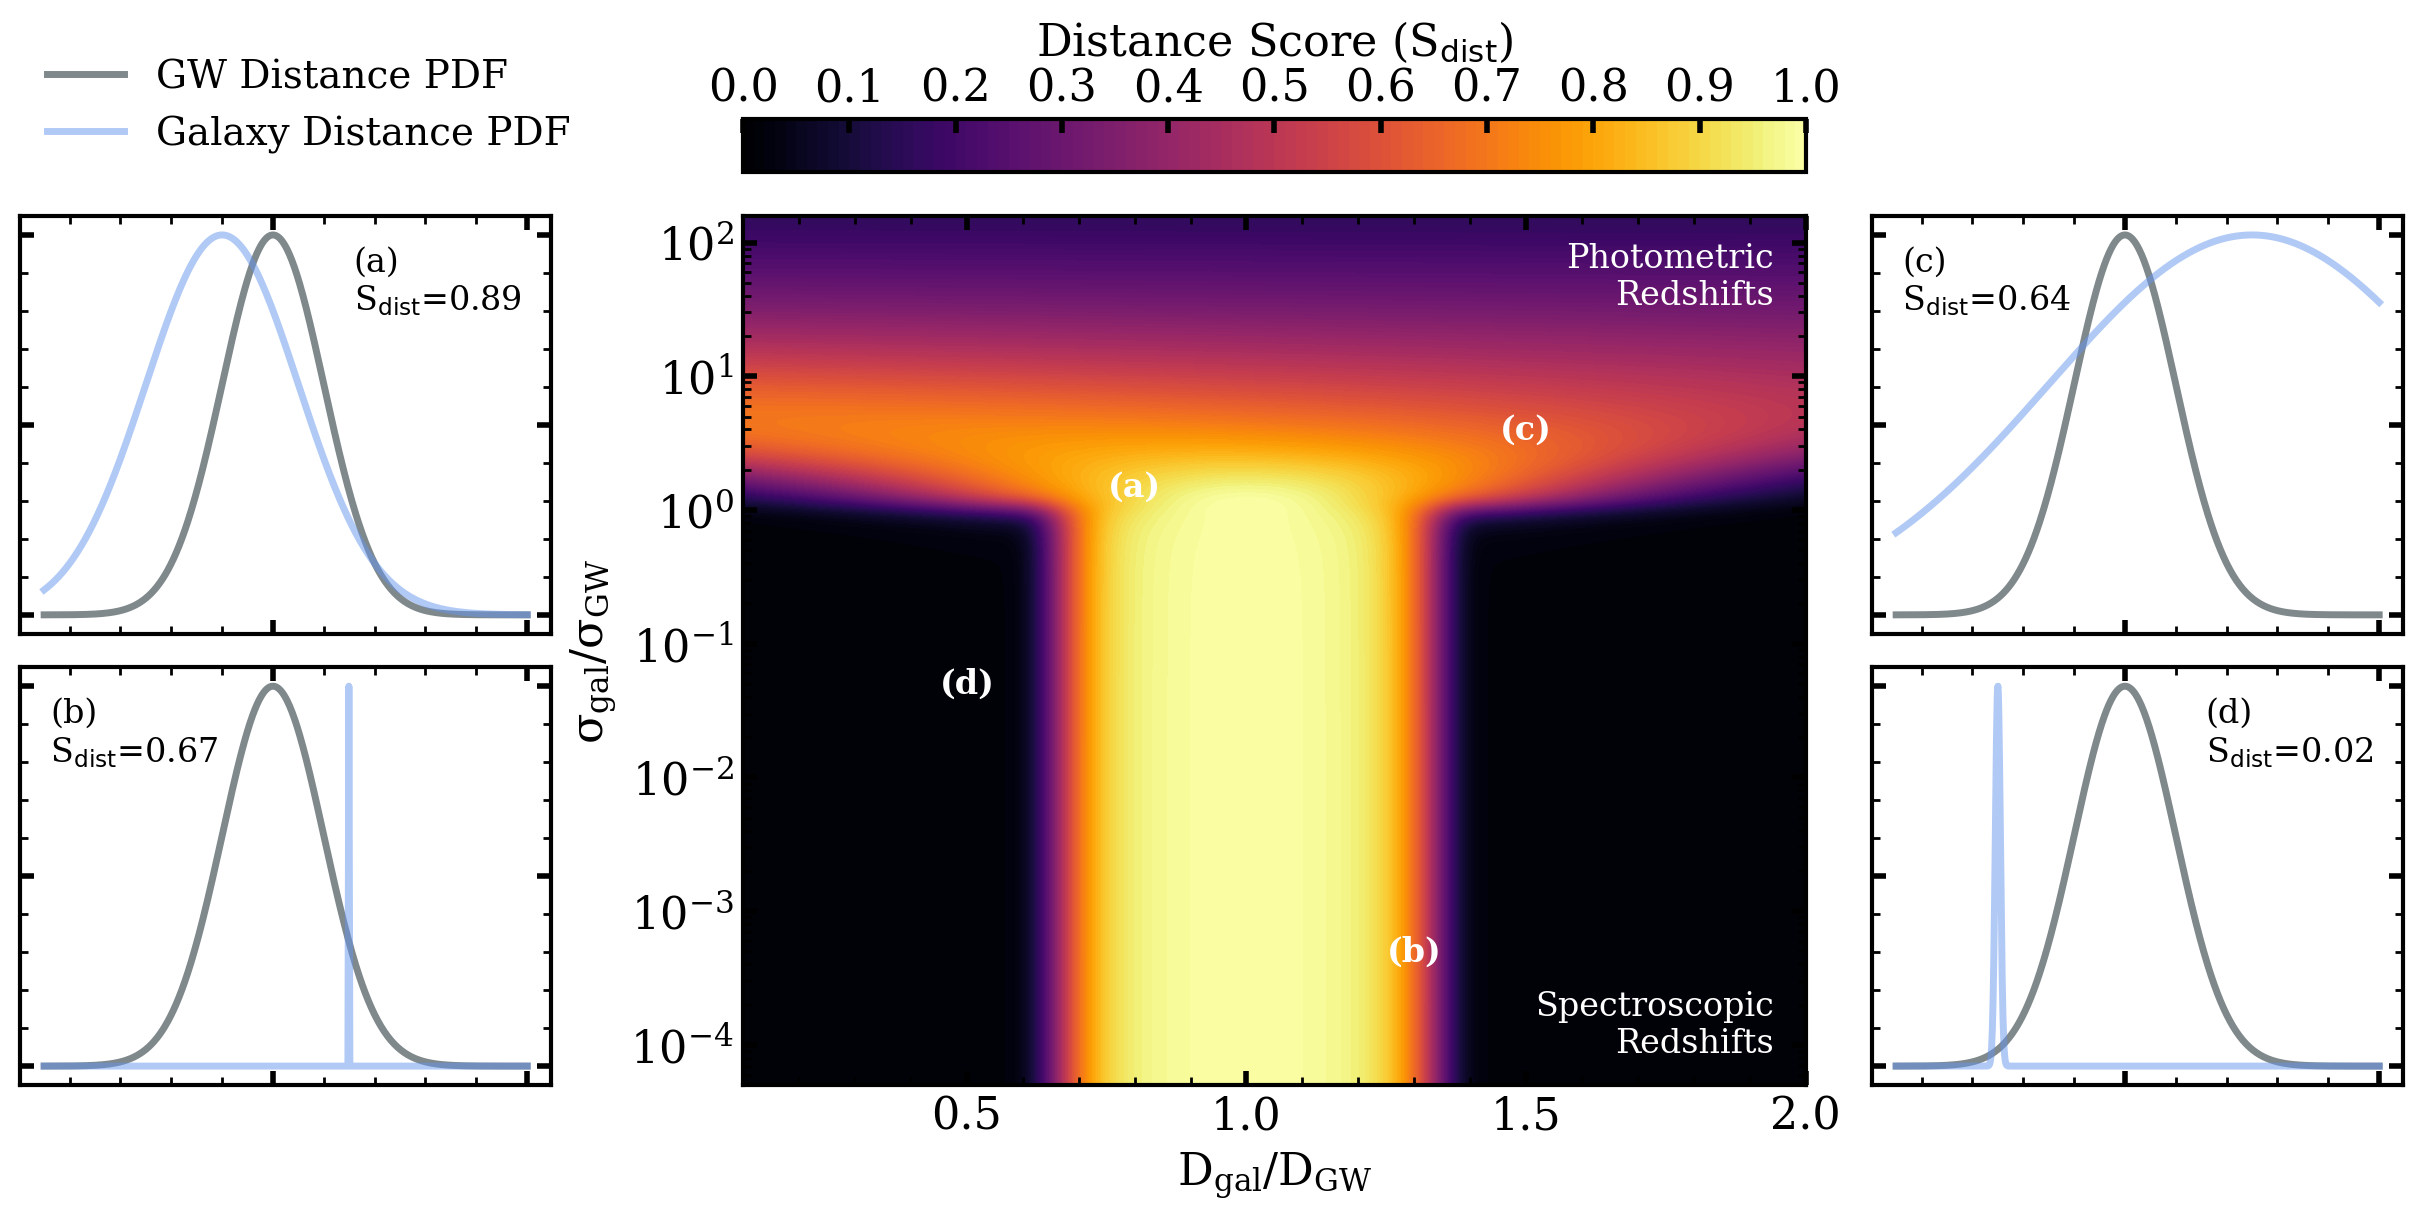

In [27]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

xnorm = gw_mean
ynorm = gw_std

mosaic = [
    ["L1", "C", "R1"],
    ["L2", "C", "R2"],
]

fig, axd = plt.subplot_mosaic(
    mosaic,
    figsize=(12, 6),
    width_ratios=[1, 2, 1],   # make the center column a bit wider
    layout="constrained",       # handles spacing and the colorbar nicely
)

# --- Center plot (your existing one) ---
ax = axd["C"]
cbar = ax.contourf(dist_grid/xnorm, std_grid/ynorm, scores, levels=np.linspace(0,1,101), cmap=plt.cm.inferno)
ax.set_ylabel(r"$\sigma_{gal}$/$\sigma_{GW}$")
ax.set_xlabel(r"$D_{gal}$/$D_{GW}$")
ax.set_yscale("log")
cb = fig.colorbar(cbar, ax=ax, label=r"Distance Score ($S_{\mathrm{dist}}$)", location="top", orientation="horizontal")
cb.set_ticks(np.arange(0, 1.01, 0.1))

# add letter labels to the 2D hist plot

#flat_idx = rng.choice(scores.size, size=4, replace=False)
#rows, cols = np.unravel_index(flat_idx, scores.shape)
d = np.array([80, 130, 150, 50])
s = np.array([30, 1e-2, 80, 1])
sc = hybrid_distance_score(gw_mean, d, gw_std, s, s)

letter_labels = {let:(d[ii],s[ii],sc[ii]) for ii,let in enumerate(["a", "b", "c", "d"])}
print(letter_labels)

for let, (dist, std, sco) in letter_labels.items():
    ax.text(dist/xnorm, std/ynorm, f"({let})", fontsize=12, color="w", ha="center", va="center", fontweight="bold")

ax.text(0.97, 0.97, "Photometric\nRedshifts", color="white", fontsize=12, ha="right", va="top", transform=ax.transAxes)
ax.text(0.97, 0.03, "Spectroscopic\nRedshifts", color="white", fontsize=12, ha="right", va="bottom", transform=ax.transAxes)

# --- Side plots ---
for k, letter in zip(["L1", "L2", "R1", "R2"], ["a", "b", "c", "d"]):    
    gw = norm.pdf(PDF_X, gw_mean, gw_std)
    gw /= gw.max()

    axd[k].plot(PDF_X, gw, alpha=0.5, label="GW Distance PDF" if k == "L1" else None )
    axd[k].set_xticklabels([])
    axd[k].set_yticklabels([])

    dist,std,sco = letter_labels[letter]

    gal = norm.pdf(PDF_X, dist, std)
    gal /= gal.max()
    
    # axd[k].text(0.03, 0.97, f"({letter})\n"+rf"$S_{{\mathrm{{dist}}}}$={sco:.2f}",
    #     transform=axd[k].transAxes,
    #     ha="left", va="top",
    #     color="k", fontsize=12)
    label = f"({letter})\n" + rf"$S_{{\mathrm{{dist}}}}$={sco:.2f}"
    axd[k].legend(
        handles=[Line2D([], [], linestyle="none")],  # invisible dummy handle
        labels=[label],
        loc="best",
        handlelength=0,      # no space reserved for the handle
        handletextpad=0,     # no gap between handle and text
        frameon=False,       # drop the box to match your plain text
        fontsize=12,
        labelcolor="k",
        # props={"weight":"bold"},
        # alignment="right"
    )
    
    axd[k].plot(PDF_X, gal, alpha=0.5, color="cornflowerblue", label="Galaxy Distance PDF" if k == "L1" else None)

fig.legend(loc="lower left", bbox_to_anchor=(0, 0.85), fontsize=14)
    
# axd["L1"].set_title("Left top")
# axd["L2"].set_title("Left bottom")
# axd["R1"].set_title("Right top")
# axd["R2"].set_title("Right bottom")

fig.savefig("score-grid.png")